# Regularized Model Evaluation - All Teams

This is the primary comparison of Elastic Net across the three cumulative predictor experiments. Ridge and Lasso are evaluated only for Experiment C, which contains the complete predictor set. All EPL clubs, including promoted teams, are retained.

## Standard workflow

1. Load and validate the shared modeling dataset.
2. Define predictors and the remaining-points target.
3. Reserve 2023/24-2025/26 as untouched test seasons.
4. Tune models with grouped leave-one-season-out validation on 2016/17-2022/23.
5. Compare validation and test metrics.
6. Render the five diagnostic views for the three Experiment C regularizers.


## 1. Imports and shared configuration


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.base import clone
from sklearn.linear_model import ElasticNet, Lasso, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 4031
DEVELOPMENT_SEASONS = list(range(2016, 2023))
TEST_SEASONS = list(range(2023, 2026))
SEASON_LABELS = {season: f"{season}/{str(season + 1)[-2:]}" for season in range(2016, 2026)}
TEAMS_TO_PLOT = [
    "Arsenal",
    "Crystal Palace",
    "Manchester City",
    "Chelsea",
    "Liverpool",
    "Tottenham",
]

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")


## 2. Load and validate the modeling data


In [2]:
def locate_dataset(filename="epl_merged_data.xlsx"):
    search_roots = [Path.cwd(), *Path.cwd().parents]
    for root in search_roots:
        candidate = root / "outputs" / filename
        if candidate.exists():
            return candidate
    raise FileNotFoundError(
        f"Could not locate outputs/{filename} from {Path.cwd().resolve()}"
    )


dataset_path = locate_dataset()
all_teams_data = pd.read_excel(dataset_path)

required_columns = {
    "Season", "Team", "Promoted", "Curr_Points", "EOS_Total_Points"
}
missing_columns = sorted(required_columns.difference(all_teams_data.columns))
if missing_columns:
    raise KeyError(f"Missing required columns: {missing_columns}")

if all_teams_data.duplicated(["Season", "Team"]).any():
    raise ValueError("The dataset contains duplicate Season-Team observations.")

all_teams_data["Remaining_Points"] = (
    all_teams_data["EOS_Total_Points"] - all_teams_data["Curr_Points"]
)

print(f"Loaded: {dataset_path.resolve()}")
print(f"Observations: {len(all_teams_data):,}")
print(f"Seasons: {all_teams_data['Season'].min()}-{all_teams_data['Season'].max()}")


Loaded: C:\Users\micha\epl_results_prediction\outputs\epl_merged_data.xlsx
Observations: 200
Seasons: 2016-2025


## 3. Define the analysis scope and predictors


In [3]:
CURRENT_PERFORMANCE_FEATURES = [
    "Curr_Avg_Win_Percentage",
    "Curr_Avg_Draw_Percentage",
    "Curr_Avg_Goals",
    "Curr_Avg_SOT",
    "Curr_Avg_Opp_Goals",
    "Curr_Avg_Opp_SOT",
    "Curr_Avg_xG",
    "Curr_Avg_xGA",
    "Curr_Avg_Deep",
    "Curr_Avg_Deep_Allowed",
    "Curr_Points",
]

PREVIOUS_SEASON_FEATURES = [
    "Prev_Total_Points",
    "Prev_Avg_Goals",
    "Prev_Avg_SOT",
    "Prev_Avg_Opp_Goals",
    "Prev_Avg_Opp_SOT",
    "Prev_Avg_xG",
    "Prev_Avg_xGA",
    "Prev_Points",
]

TRANSFER_FEATURES = [
    "Fee_Spending",
    "Fee_Earnings",
    "Permanent_In_Count",
    "Permanent_Out_Count",
]

TARGET = "Remaining_Points"



modeling_data = all_teams_data.copy()
print(f"Analysis scope: all {len(modeling_data):,} observations")
print(f"Promoted observations included: {int(modeling_data['Promoted'].sum())}")



EXPERIMENTS = {
    "Experiment A: Current performance": CURRENT_PERFORMANCE_FEATURES,
    "Experiment B: Current + previous season": CURRENT_PERFORMANCE_FEATURES + PREVIOUS_SEASON_FEATURES + ["Promoted"],
    "Experiment C: Current + previous + transfers": CURRENT_PERFORMANCE_FEATURES + PREVIOUS_SEASON_FEATURES + ["Promoted"] + TRANSFER_FEATURES,
}

for experiment_name, features in EXPERIMENTS.items():
    print(f"{experiment_name}: {len(features)} predictors")


Analysis scope: all 200 observations
Promoted observations included: 30
Experiment A: Current performance: 11 predictors
Experiment B: Current + previous season: 20 predictors
Experiment C: Current + previous + transfers: 24 predictors


## 4. Create development, validation, and test samples


In [4]:
development = (
    modeling_data.loc[modeling_data["Season"].isin(DEVELOPMENT_SEASONS)]
    .copy()
    .reset_index(drop=True)
)
test_data = (
    modeling_data.loc[modeling_data["Season"].isin(TEST_SEASONS)]
    .copy()
    .reset_index(drop=True)
)

if development.empty or test_data.empty:
    raise ValueError("Development or test data is empty.")

# Grouped leave-one-season-out validation keeps each season intact. The final
# three seasons remain completely untouched until final evaluation.
cv_splits = []
fold_rows = []
for fold_number, validation_season in enumerate(DEVELOPMENT_SEASONS, start=1):
    train_indices = np.flatnonzero(development["Season"].ne(validation_season))
    validation_indices = np.flatnonzero(development["Season"].eq(validation_season))
    if not len(validation_indices):
        raise ValueError(f"No validation observations for season {validation_season}.")
    cv_splits.append((train_indices, validation_indices))
    fold_rows.append(
        {
            "Fold": fold_number,
            "Validation_Season": SEASON_LABELS[validation_season],
            "Training_Observations": len(train_indices),
            "Validation_Observations": len(validation_indices),
        }
    )

fold_summary = pd.DataFrame(fold_rows)
print(f"Development observations: {len(development):,}")
print(f"Test observations: {len(test_data):,}")


Development observations: 140
Test observations: 60


## 5. Define the regularized regression models


In [5]:
MODEL_SPECS = {
    "Elastic Net": {
        "pipeline": Pipeline(
            [
                ("scaler", StandardScaler()),
                (
                    "model",
                    ElasticNet(
                        max_iter=100_000,
                        tol=1e-4,
                        random_state=RANDOM_STATE,
                    ),
                ),
            ]
        ),
        "grid": {
            "model__alpha": np.logspace(-3, 2, 25),
            "model__l1_ratio": [0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 1.00],
        },
    },
    "Ridge": {
        "pipeline": Pipeline(
            [("scaler", StandardScaler()), ("model", Ridge())]
        ),
        "grid": {"model__alpha": np.logspace(-3, 3, 50)},
    },
    "Lasso": {
        "pipeline": Pipeline(
            [
                ("scaler", StandardScaler()),
                (
                    "model",
                    Lasso(
                        max_iter=100_000,
                        tol=1e-4,
                        random_state=RANDOM_STATE,
                    ),
                ),
            ]
        ),
        "grid": {"model__alpha": np.logspace(-3, 2, 50)},
    },
}

SCORING = {
    "mse": "neg_mean_squared_error",
    "mae": "neg_mean_absolute_error",
}


## 6. Reusable evaluation procedure


In [6]:
def evaluate_model(experiment_name, model_name, features):
    missing = sorted(set(features).difference(modeling_data.columns))
    if missing:
        raise KeyError(f"{experiment_name} is missing predictors: {missing}")
    if modeling_data[features].isna().any().any():
        raise ValueError(f"{experiment_name} contains missing predictor values.")

    model_spec = MODEL_SPECS[model_name]
    search = GridSearchCV(
        estimator=clone(model_spec["pipeline"]),
        param_grid=model_spec["grid"],
        scoring=SCORING,
        refit="mse",
        cv=cv_splits,
        n_jobs=-1,
        error_score="raise",
    )
    X_development = development[features]
    y_development = development[TARGET]
    search.fit(X_development, y_development)

    validation_rows = []
    for fold_number, (train_indices, validation_indices) in enumerate(cv_splits, start=1):
        fold_model = clone(search.best_estimator_)
        fold_model.fit(
            X_development.iloc[train_indices],
            y_development.iloc[train_indices],
        )
        actual = y_development.iloc[validation_indices]
        predicted = fold_model.predict(X_development.iloc[validation_indices])
        mse = mean_squared_error(actual, predicted)
        validation_season = development.iloc[validation_indices]["Season"].iat[0]
        validation_rows.append(
            {
                "Fold": fold_number,
                "Validation_Season": SEASON_LABELS[validation_season],
                "MSE": mse,
                "MAE": mean_absolute_error(actual, predicted),
                "RMSE": np.sqrt(mse),
            }
        )
    validation_metrics = pd.DataFrame(validation_rows)

    final_pipeline = search.best_estimator_
    predictions = final_pipeline.predict(test_data[features])
    test_results = test_data[
        [
            "Season",
            "Team",
            "Promoted",
            "Curr_Points",
            "Remaining_Points",
            "EOS_Total_Points",
        ]
    ].copy()
    test_results["Predicted_Remaining_Points"] = predictions
    test_results["Predicted_Final_Points"] = test_results["Curr_Points"] + predictions
    test_results["Final_Points_Residual"] = (
        test_results["EOS_Total_Points"] - test_results["Predicted_Final_Points"]
    )
    test_results["Absolute_Final_Points_Error"] = (
        test_results["Final_Points_Residual"].abs()
    )
    test_results["Season_Label"] = test_results["Season"].map(SEASON_LABELS)

    test_mse = mean_squared_error(
        test_results["EOS_Total_Points"], test_results["Predicted_Final_Points"]
    )
    test_mae = mean_absolute_error(
        test_results["EOS_Total_Points"], test_results["Predicted_Final_Points"]
    )

    fitted_model = final_pipeline.named_steps["model"]
    coefficient_table = pd.DataFrame(
        {
            "Feature": features,
            "Standardized_Coefficient": fitted_model.coef_,
        }
    )
    coefficient_table["Absolute_Coefficient"] = (
        coefficient_table["Standardized_Coefficient"].abs()
    )
    coefficient_table["Selected"] = ~np.isclose(
        coefficient_table["Standardized_Coefficient"], 0.0, atol=1e-10
    )
    coefficient_table = coefficient_table.sort_values(
        "Absolute_Coefficient", ascending=False
    ).reset_index(drop=True)

    return {
        "Label": f"{model_name} - {experiment_name}",
        "Experiment": experiment_name,
        "Model": model_name,
        "Features": features,
        "Best_Parameters": search.best_params_,
        "Validation_Metrics": validation_metrics,
        "Validation_MSE": validation_metrics["MSE"].mean(),
        "Validation_MAE": validation_metrics["MAE"].mean(),
        "Validation_RMSE": np.sqrt(validation_metrics["MSE"].mean()),
        "Test_Results": test_results,
        "Test_MSE": test_mse,
        "Test_MAE": test_mae,
        "Test_RMSE": np.sqrt(test_mse),
        "Coefficient_Table": coefficient_table,
    }

def comparison_row(results):
    parameters = results["Best_Parameters"]
    return {
        "Experiment": results["Experiment"],
        "Model": results["Model"],
        "Predictors": len(results["Features"]),
        "Selected_Predictors": int(
            results["Coefficient_Table"]["Selected"].sum()
        ),
        "Validation_MSE": results["Validation_MSE"],
        "Validation_MAE": results["Validation_MAE"],
        "Validation_RMSE": results["Validation_RMSE"],
        "Test_MSE": results["Test_MSE"],
        "Test_MAE": results["Test_MAE"],
        "Test_RMSE": results["Test_RMSE"],
        "Best_Alpha": parameters.get("model__alpha", np.nan),
        "L1_Ratio": parameters.get("model__l1_ratio", np.nan),
    }


## 7. Fit the standardized model grid


In [7]:
MODEL_EXPERIMENT_RUNS = [
    ("Experiment A: Current performance", "Elastic Net"),
    ("Experiment B: Current + previous season", "Elastic Net"),
    ("Experiment C: Current + previous + transfers", "Elastic Net"),
    ("Experiment C: Current + previous + transfers", "Ridge"),
    ("Experiment C: Current + previous + transfers", "Lasso"),
]

all_results = []
for experiment_name, model_name in MODEL_EXPERIMENT_RUNS:
    print(f"Fitting {model_name} - {experiment_name} ...")
    all_results.append(
        evaluate_model(
            experiment_name,
            model_name,
            EXPERIMENTS[experiment_name],
        )
    )

print(f"Completed {len(all_results)} fitted model-experiment combinations.")


Fitting Elastic Net - Experiment A: Current performance ...


Fitting Elastic Net - Experiment B: Current + previous season ...


Fitting Elastic Net - Experiment C: Current + previous + transfers ...


Fitting Ridge - Experiment C: Current + previous + transfers ...


Fitting Lasso - Experiment C: Current + previous + transfers ...


Completed 5 fitted model-experiment combinations.


## 8. Compare fitted results

Validation metrics determine model selection; test metrics describe final generalization and are not used for tuning.


In [8]:
comparison = pd.DataFrame([comparison_row(result) for result in all_results])
comparison = comparison.sort_values(["Validation_MSE", "Validation_MAE"]).reset_index(drop=True)
display(comparison)


,Experiment,Model,Predictors,Selected_Predictors,Validation_MSE,Validation_MAE,Validation_RMSE,Test_MSE,Test_MAE,Test_RMSE,Best_Alpha,L1_Ratio
0,Experiment C: Current + previous + transfers,Ridge,24,24,73.418,6.930,8.568,81.832,7.519,9.046,104.811,NaN
1,Experiment C: Current + previous + transfers,Elastic Net,24,24,73.540,6.929,8.576,82.026,7.523,9.057,0.825,0.050
2,Experiment B: Current + previous season,Elastic Net,20,20,77.427,7.186,8.799,86.821,7.642,9.318,0.825,0.050
3,Experiment C: Current + previous + transfers,Lasso,24,14,78.223,7.056,8.844,83.306,7.436,9.127,0.450,NaN
4,Experiment A: Current performance,Elastic Net,11,11,84.682,7.589,9.202,96.870,8.061,9.842,0.825,0.050


## 9. Standardized predictor coefficients

The fitted pipelines standardize every predictor before estimation, so each coefficient represents the expected change in predicted remaining points associated with a one-standard-deviation increase in that predictor, holding the other predictors constant. Positive coefficients increase the forecast; negative coefficients decrease it. Exact zeros indicate predictors removed by an L1 penalty.

The matrix includes every fitted implementation in this notebook. Predictors are ordered by their largest absolute coefficient across the displayed models.

In [9]:
coefficient_series = []
for result in all_results:
    column_label = f"{result['Model']} | {result['Experiment']}"
    series = (
        result["Coefficient_Table"]
        .set_index("Feature")["Standardized_Coefficient"]
        .rename(column_label)
    )
    coefficient_series.append(series)

coefficient_matrix = pd.concat(coefficient_series, axis=1)
coefficient_matrix["Largest_Absolute_Coefficient"] = (
    coefficient_matrix.abs().max(axis=1)
)
coefficient_matrix = (
    coefficient_matrix
    .sort_values("Largest_Absolute_Coefficient", ascending=False)
    .drop(columns="Largest_Absolute_Coefficient")
)

display(coefficient_matrix)


,Elastic Net | Experiment A: Current performance,Elastic Net | Experiment B: Current + previous season,Elastic Net | Experiment C: Current + previous + transfers,Ridge | Experiment C: Current + previous + transfers,Lasso | Experiment C: Current + previous + transfers
Feature,,,,,
Curr_Avg_Win_Percentage,1.412,1.199,1.090,1.094,3.511
Prev_Avg_Goals,NaN,1.261,1.190,1.221,2.865
Permanent_In_Count,NaN,NaN,-1.010,-1.042,-1.556
Curr_Avg_Deep,1.520,1.055,1.013,1.022,1.370
Fee_Spending,NaN,NaN,0.917,0.955,1.331
Curr_Avg_SOT,1.263,0.811,0.702,0.700,0.000
Curr_Avg_Draw_Percentage,-1.253,-0.884,-0.832,-0.857,-0.848
Curr_Points,1.157,0.821,0.750,0.748,0.754
Promoted,NaN,-1.116,-0.917,-0.951,-0.851


## 10. Experiment C five-chart diagnostic suite

Detailed diagnostics are reserved for the final full-predictor specification: Experiment C Elastic Net, Ridge, and Lasso. Experiments A and B remain in the comparison table as feature-set tests. Each Experiment C model receives: (1) actual versus predicted final points, (2) prediction-error bands, (3) residuals, (4) the six requested team panels, and (5) the latest test season across all clubs.

In [10]:
def plot_standard_diagnostics(results, teams=TEAMS_TO_PLOT):
    """Render the five required test diagnostic views."""
    data = results["Test_Results"].copy()
    title = results["Label"]
    season_order = [SEASON_LABELS[season] for season in TEST_SEASONS]
    season_colors = dict(zip(season_order, ["#4C78A8", "#F28E2B", "#59A14F"]))

    # 1. Actual versus predicted final points.
    actual = data["EOS_Total_Points"]
    predicted = data["Predicted_Final_Points"]
    lower = min(actual.min(), predicted.min()) - 2
    upper = max(actual.max(), predicted.max()) + 2
    line = np.linspace(lower, upper, 200)
    fig, ax = plt.subplots(figsize=(9, 8))
    ax.fill_between(line, line - 5, line + 5, color="0.85", alpha=0.55, label="Within 5 points")
    ax.plot(line, line, "--", color="black", linewidth=1.7, label="Perfect prediction")
    for season_label in season_order:
        season_data = data.loc[data["Season_Label"].eq(season_label)]
        ax.scatter(
            season_data["EOS_Total_Points"],
            season_data["Predicted_Final_Points"],
            s=60,
            alpha=0.85,
            color=season_colors[season_label],
            label=season_label,
        )
    ax.text(
        0.03,
        0.96,
        f"MAE: {results['Test_MAE']:.2f} points\nRMSE: {results['Test_RMSE']:.2f} points",
        transform=ax.transAxes,
        va="top",
        fontsize=11,
    )
    ax.set(xlabel="Actual final-season points", ylabel="Predicted final-season points", title=f"{title}: Actual vs. Predicted Final Points")
    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.legend(title="Test season", loc="lower right")
    plt.tight_layout()
    plt.show()

    # 2. Share of predictions within the requested error bands.
    def accuracy_shares(frame):
        errors = frame["Absolute_Final_Points_Error"]
        return pd.Series(
            {
                "Within 5 points": errors.le(5).mean() * 100,
                "6 to 10 points": errors.gt(5).mul(errors.le(10)).mean() * 100,
                "More than 10 points": errors.gt(10).mean() * 100,
            }
        )

    accuracy = pd.DataFrame(
        [accuracy_shares(data).rename("Overall")]
        + [
            accuracy_shares(data.loc[data["Season_Label"].eq(label)]).rename(label)
            for label in reversed(season_order)
        ]
    )
    colors = ["#3E8E62", "#E5AA2B", "#C95756"]
    ax = accuracy.plot(kind="barh", stacked=True, figsize=(11, 5.5), color=colors, width=0.8)
    for container in ax.containers:
        labels = [f"{bar.get_width():.0f}%" if bar.get_width() >= 8 else "" for bar in container]
        ax.bar_label(container, labels=labels, label_type="center", color="white", weight="bold")
    ax.set(xlim=(0, 100), xlabel="Share of clubs in the test sample (%)", ylabel="Season", title=f"{title}: How Close Were the Final-Points Predictions?")
    ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.01), frameon=False)
    plt.tight_layout()
    plt.show()

    # 3. Residuals against predicted remaining points.
    fig, ax = plt.subplots(figsize=(8, 6))
    for season_label in season_order:
        season_data = data.loc[data["Season_Label"].eq(season_label)]
        ax.scatter(
            season_data["Predicted_Remaining_Points"],
            season_data["Final_Points_Residual"],
            s=55,
            alpha=0.8,
            color=season_colors[season_label],
            label=season_label,
        )
    ax.axhline(0, linestyle="--", color="black")
    ax.set(xlabel="Predicted remaining points", ylabel="Residual (actual - predicted)", title=f"{title}: Test Residuals")
    ax.legend(title="Test season")
    plt.tight_layout()
    plt.show()

    # 4. Six specified clubs across test seasons.
    available_teams = [team for team in teams if team in set(data["Team"])]
    missing_teams = sorted(set(teams).difference(available_teams))
    if missing_teams:
        print(f"Teams unavailable for {title}: {missing_teams}")
    fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True, sharey=True)
    for ax, team in zip(axes.flat, available_teams):
        team_data = data.loc[data["Team"].eq(team)].sort_values("Season")
        ax.plot(team_data["Season_Label"], team_data["EOS_Total_Points"], marker="o", linewidth=2, label="Actual final points")
        ax.plot(team_data["Season_Label"], team_data["Predicted_Final_Points"], marker="s", linestyle="--", linewidth=2, label="Predicted final points")
        ax.set_title(team)
        ax.tick_params(axis="x", rotation=25)
    for ax in axes[:, 0]:
        ax.set_ylabel("Final points")
    for ax in axes[-1, :]:
        ax.set_xlabel("Season")
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 0.96))
    fig.suptitle(f"{title}: Team Predictions Across Test Seasons", y=0.995)
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    plt.show()

    # 5. Latest test season, all clubs ordered by actual final points.
    latest_season = max(TEST_SEASONS)
    latest = data.loc[data["Season"].eq(latest_season)].sort_values("EOS_Total_Points", ascending=False)
    x = np.arange(len(latest))
    fig, ax = plt.subplots(figsize=(16, 6))
    ax.plot(x, latest["EOS_Total_Points"], marker="o", linewidth=2, label="Actual final points")
    ax.plot(x, latest["Predicted_Final_Points"], marker="s", linestyle="--", linewidth=2, label="Predicted final points")
    ax.set_xticks(x, latest["Team"], rotation=60, ha="right")
    for tick_label in ax.get_xticklabels():
        if tick_label.get_text() in teams:
            tick_label.set_weight("bold")
    ax.set(xlabel="Team, ordered by actual final points", ylabel="Final points", title=f"{title}: {SEASON_LABELS[latest_season]} Actual vs. Predicted Final Points")
    ax.legend()
    plt.tight_layout()
    plt.show()


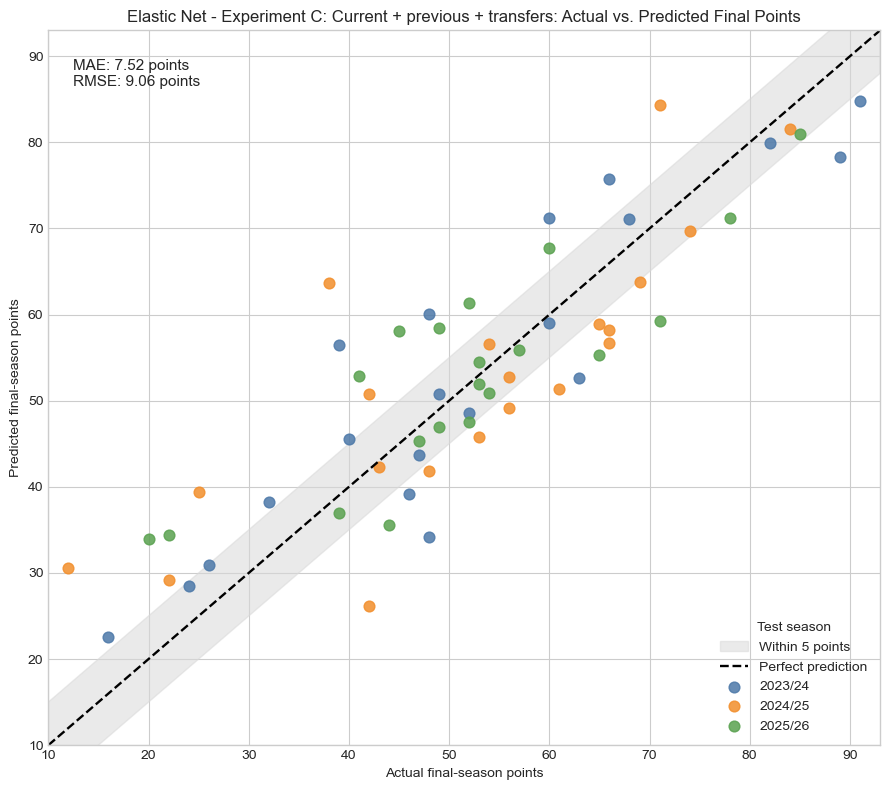

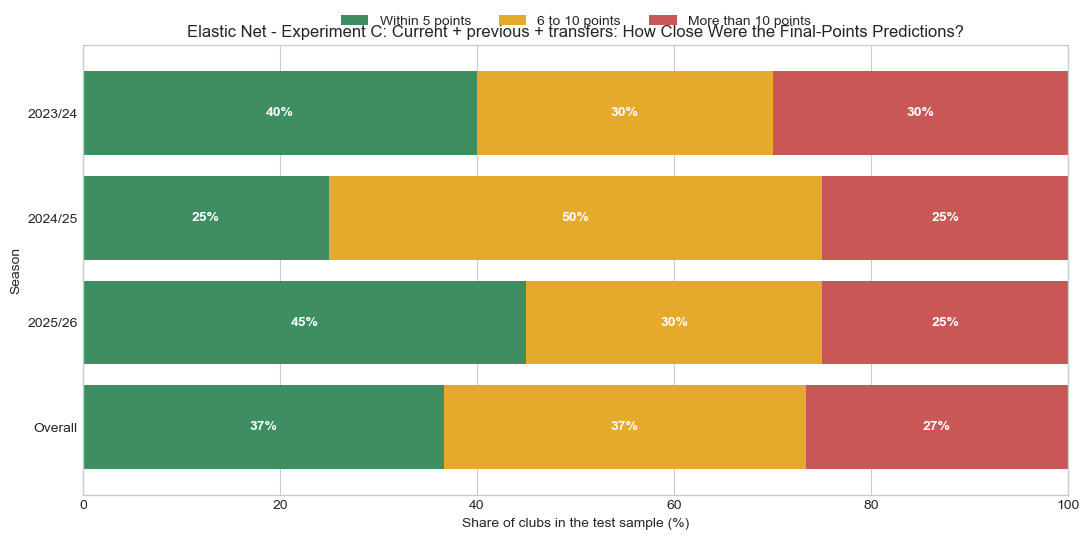

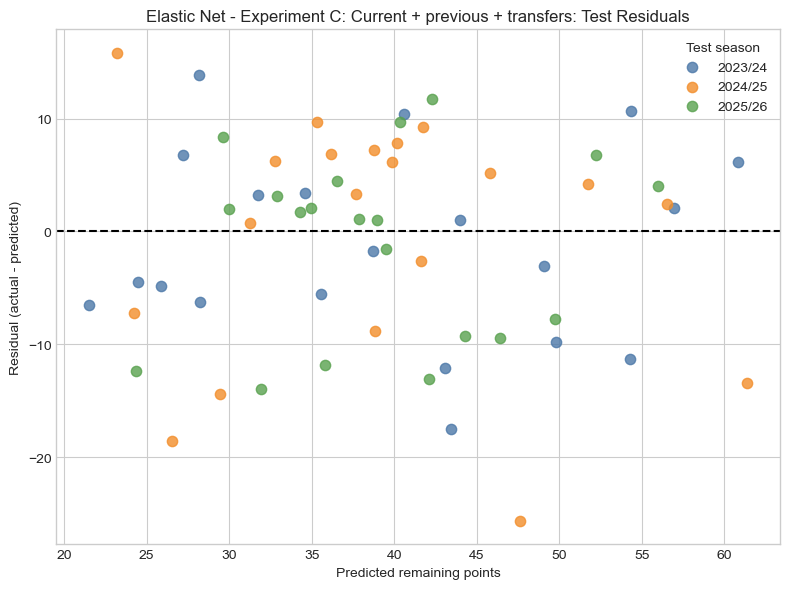

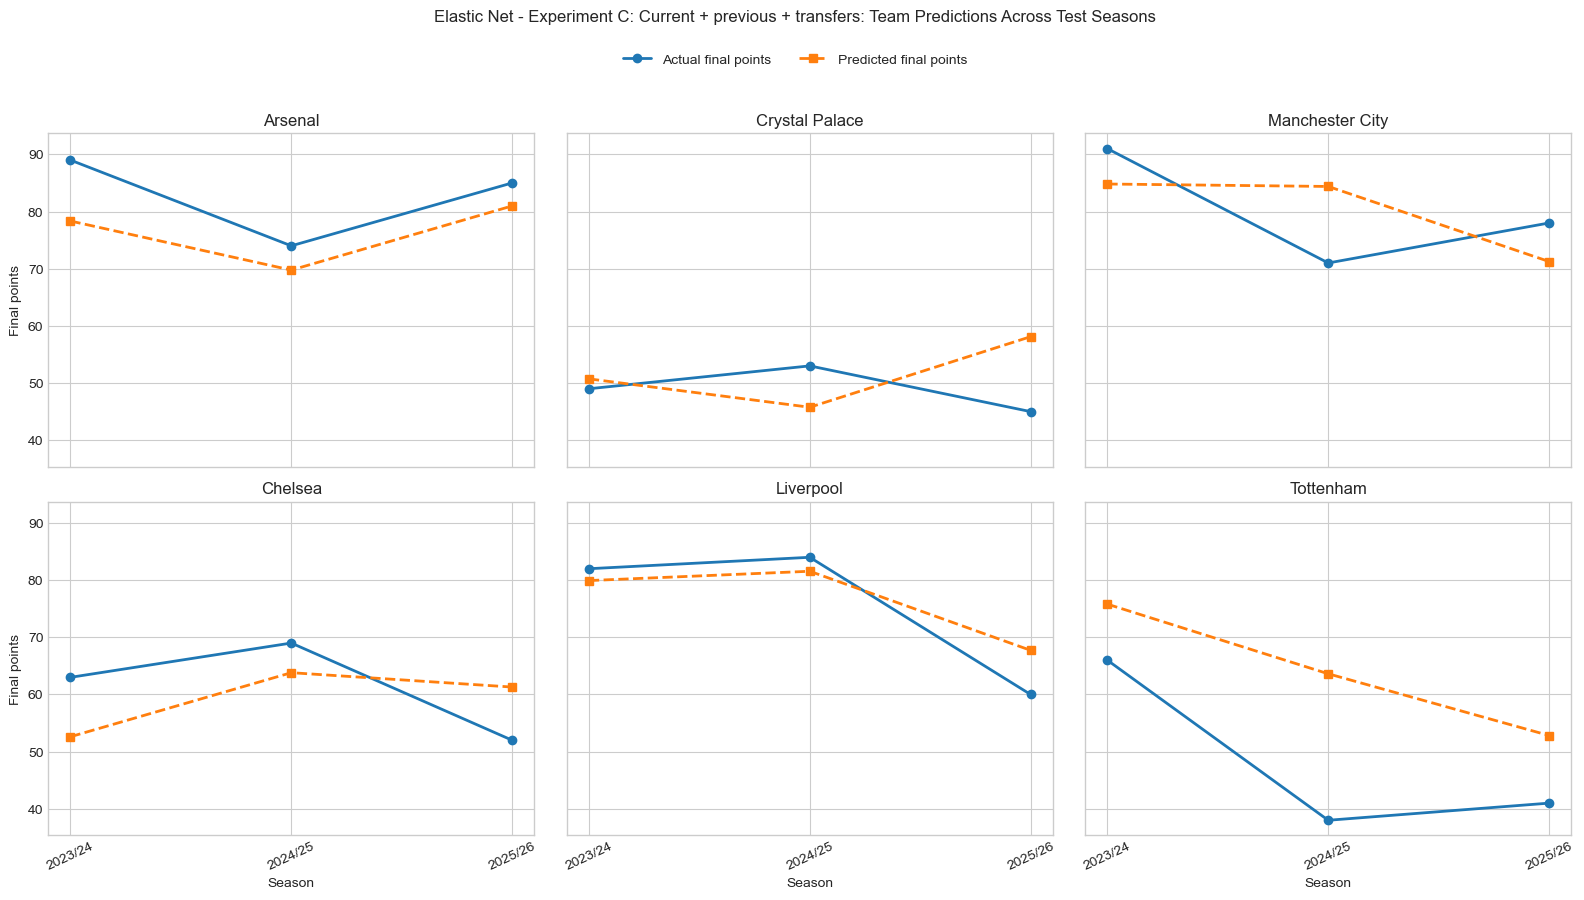

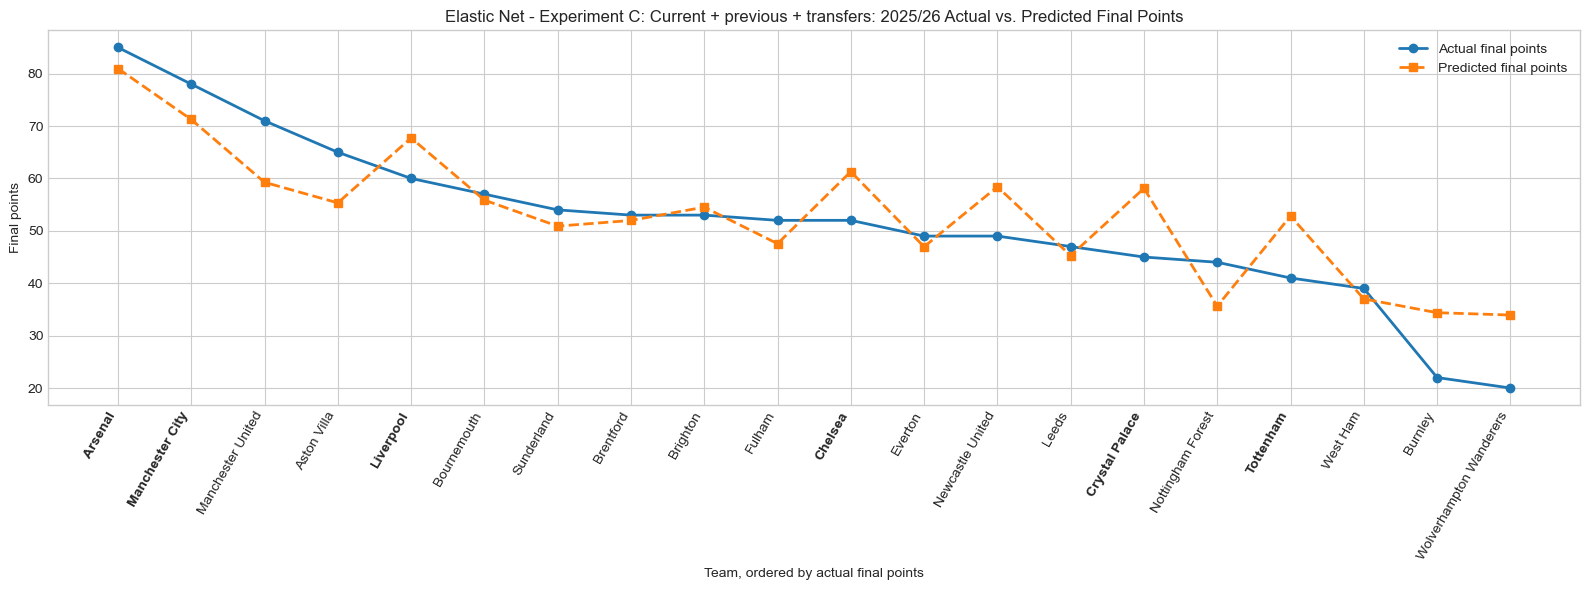

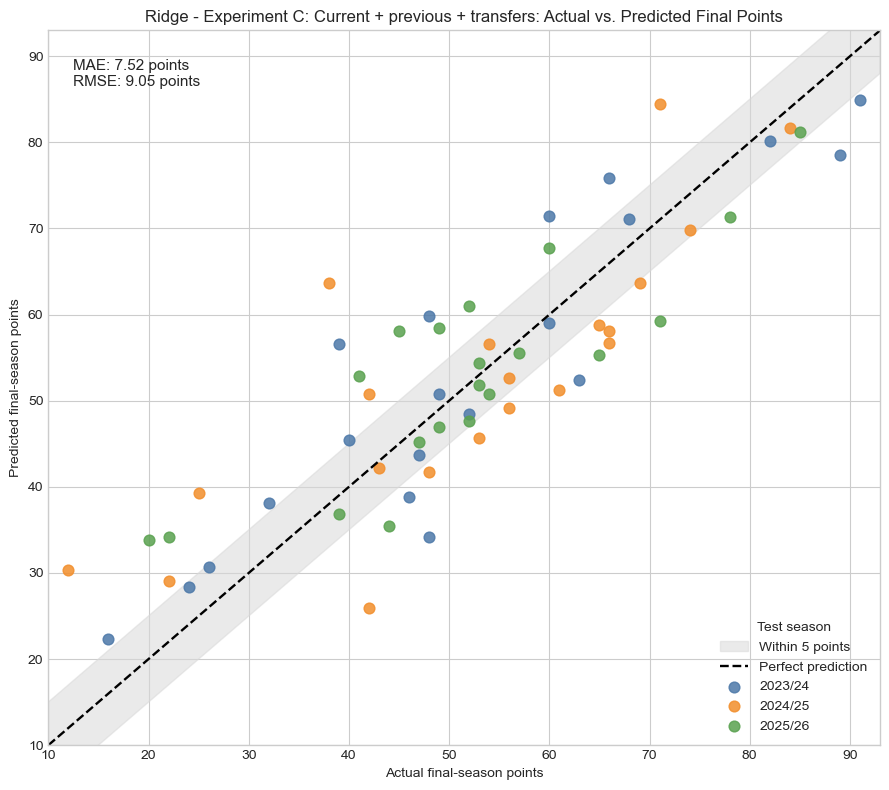

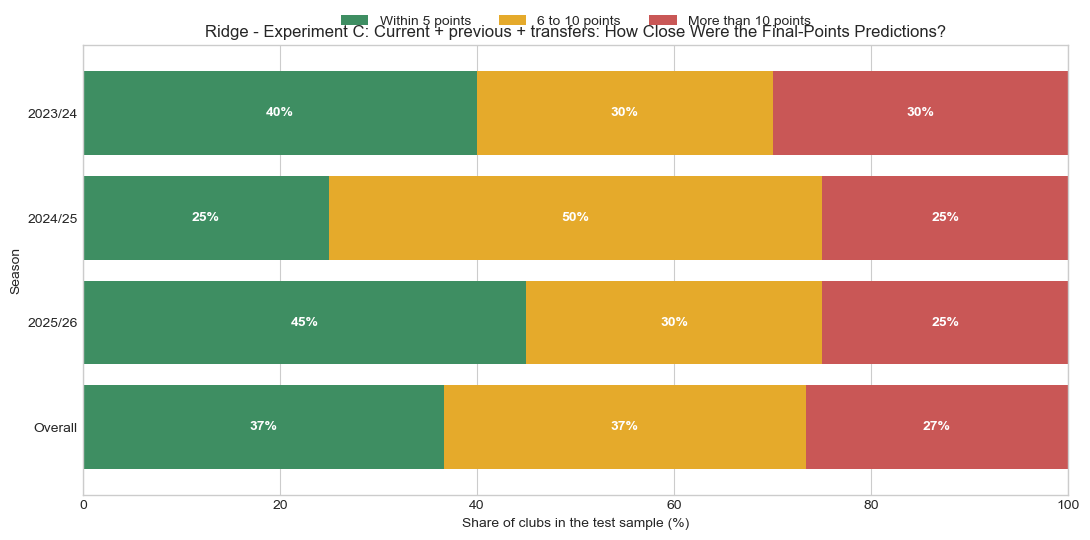

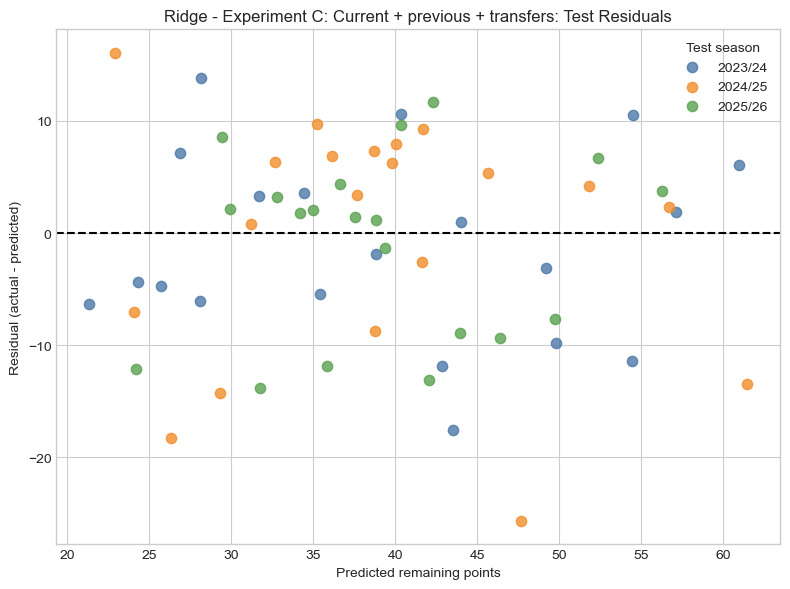

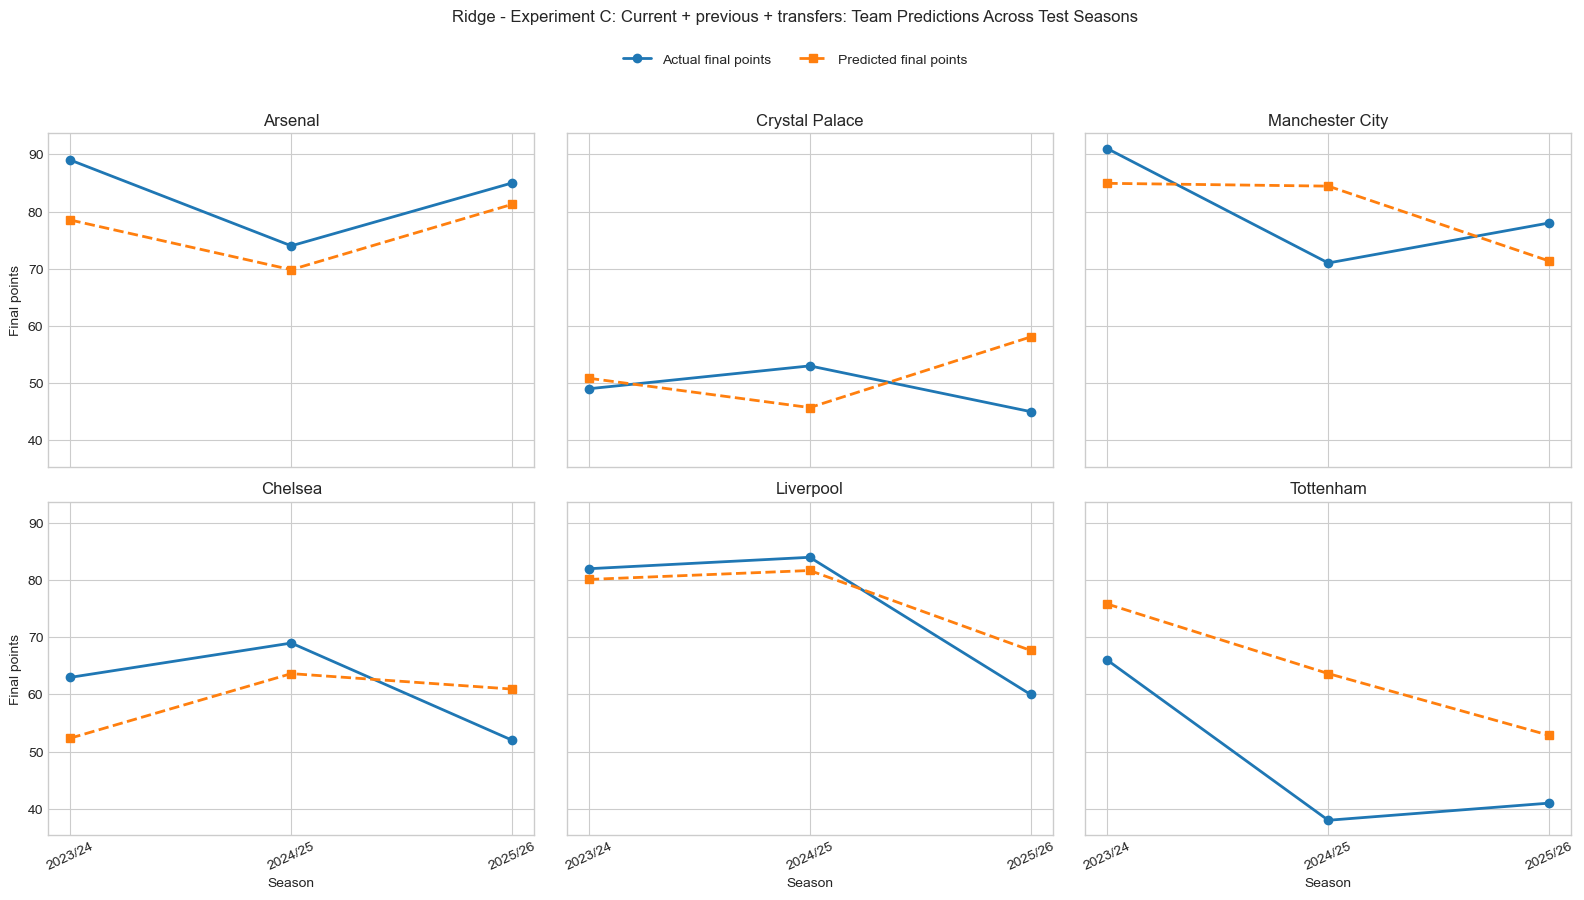

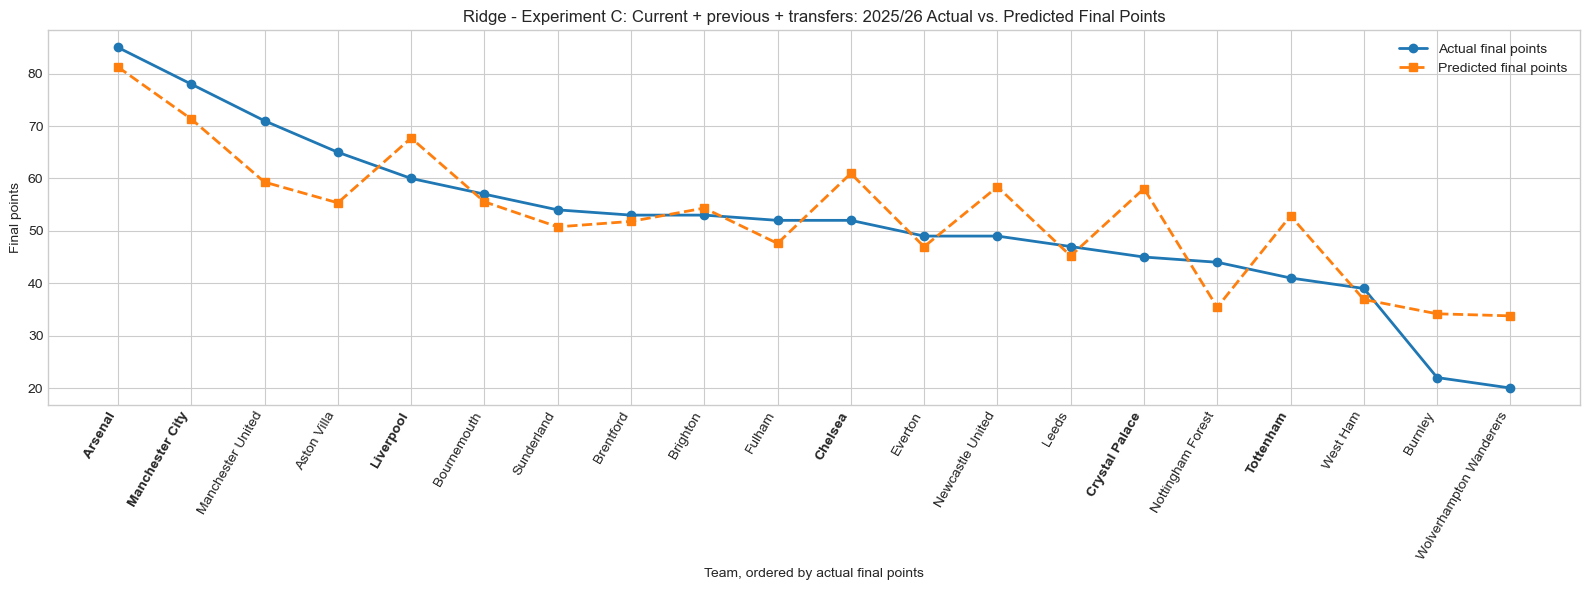

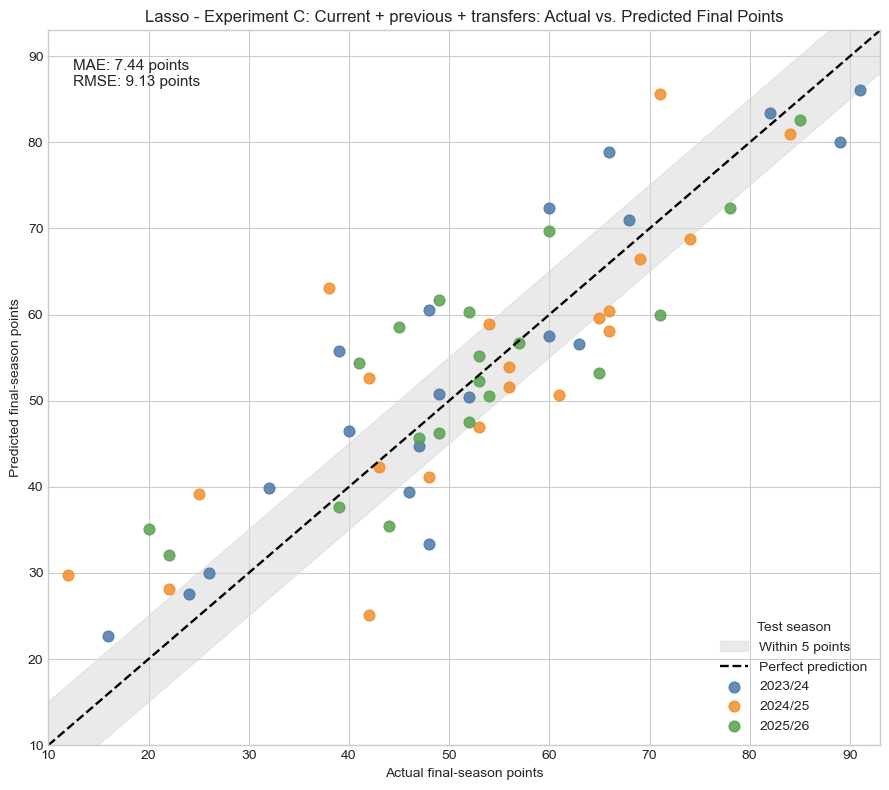

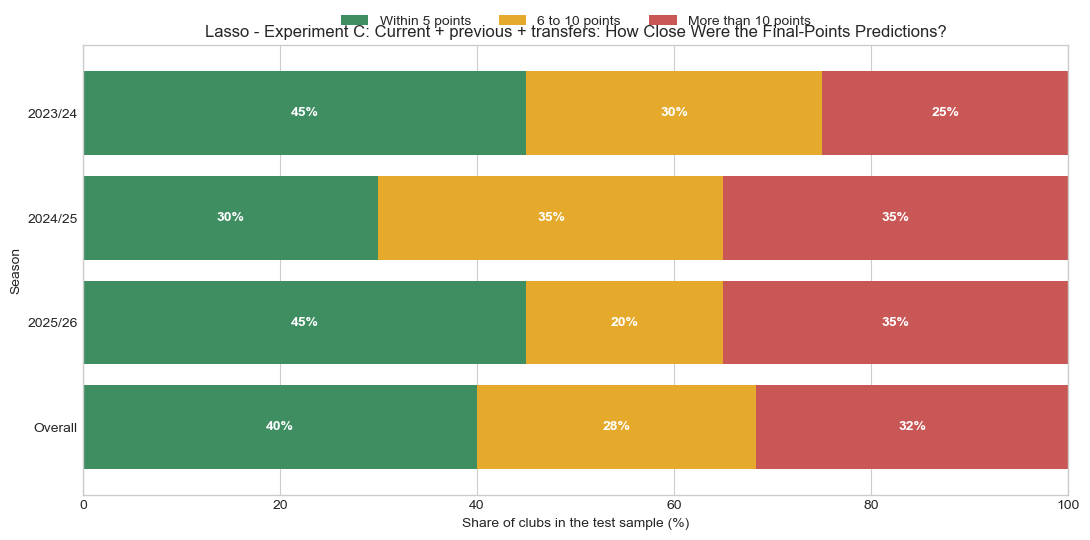

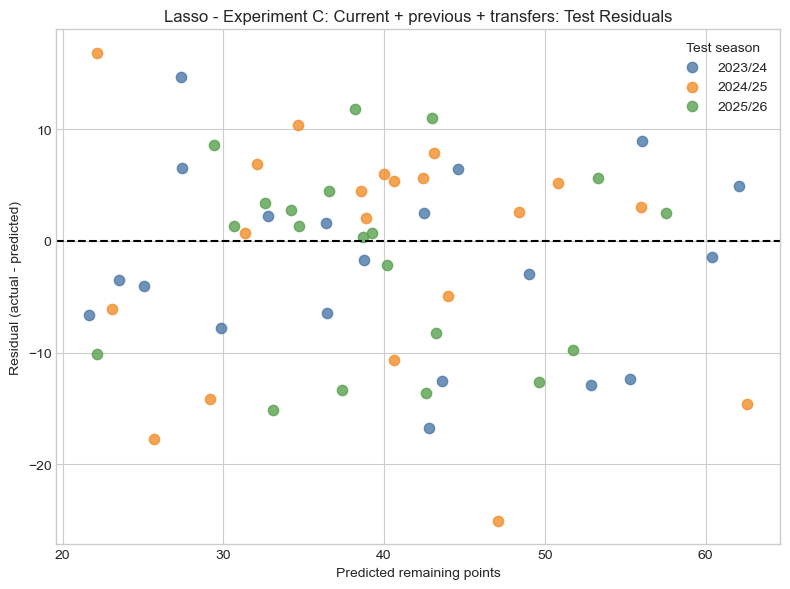

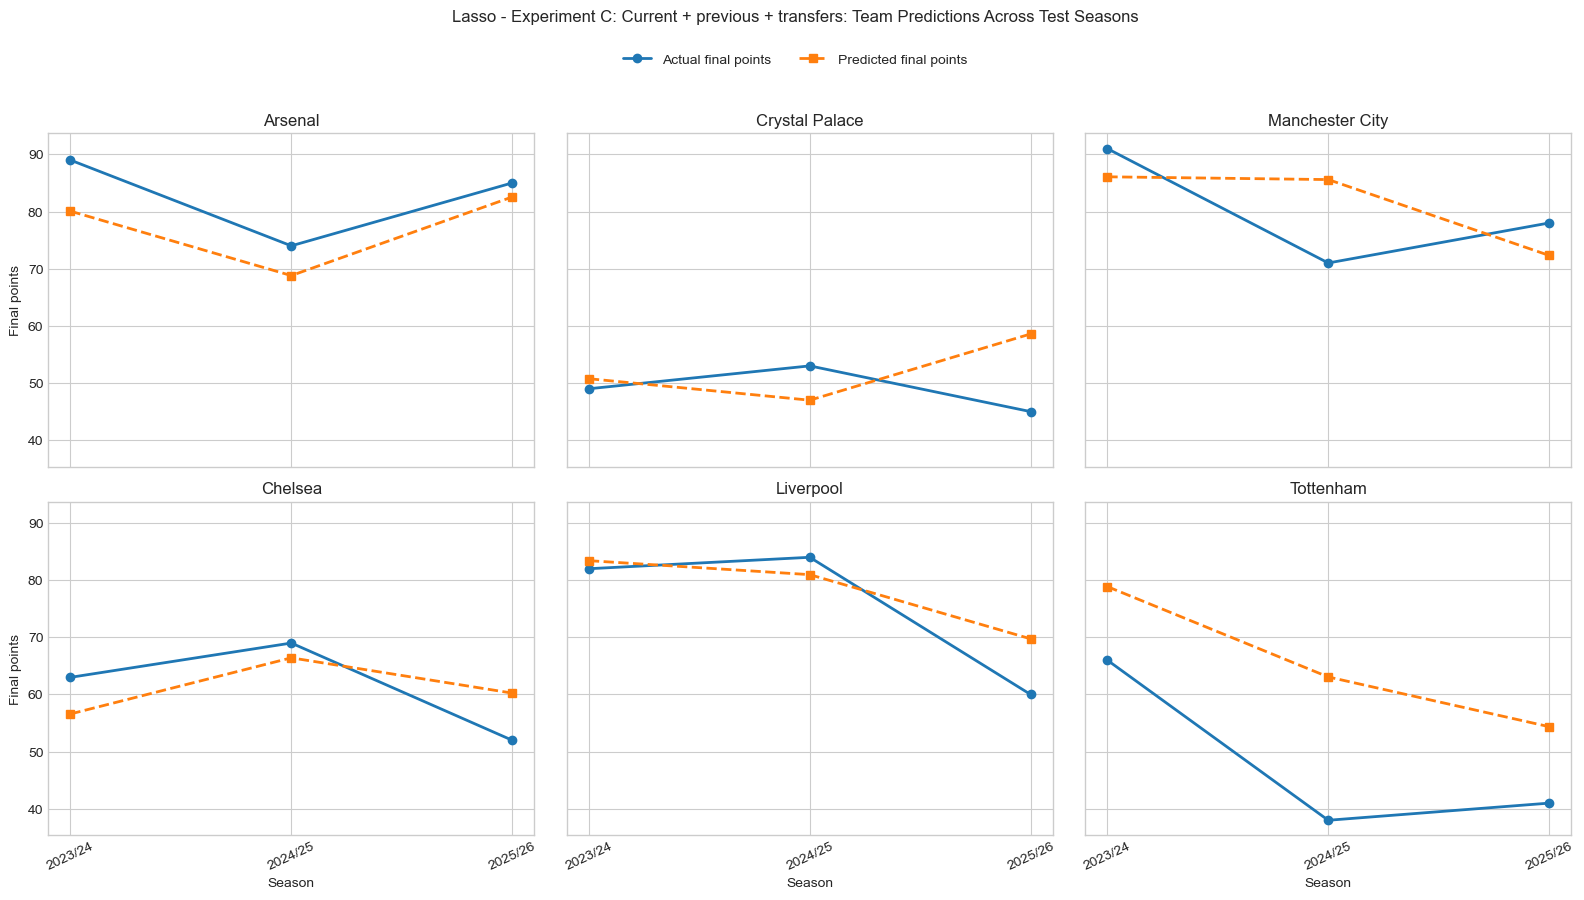

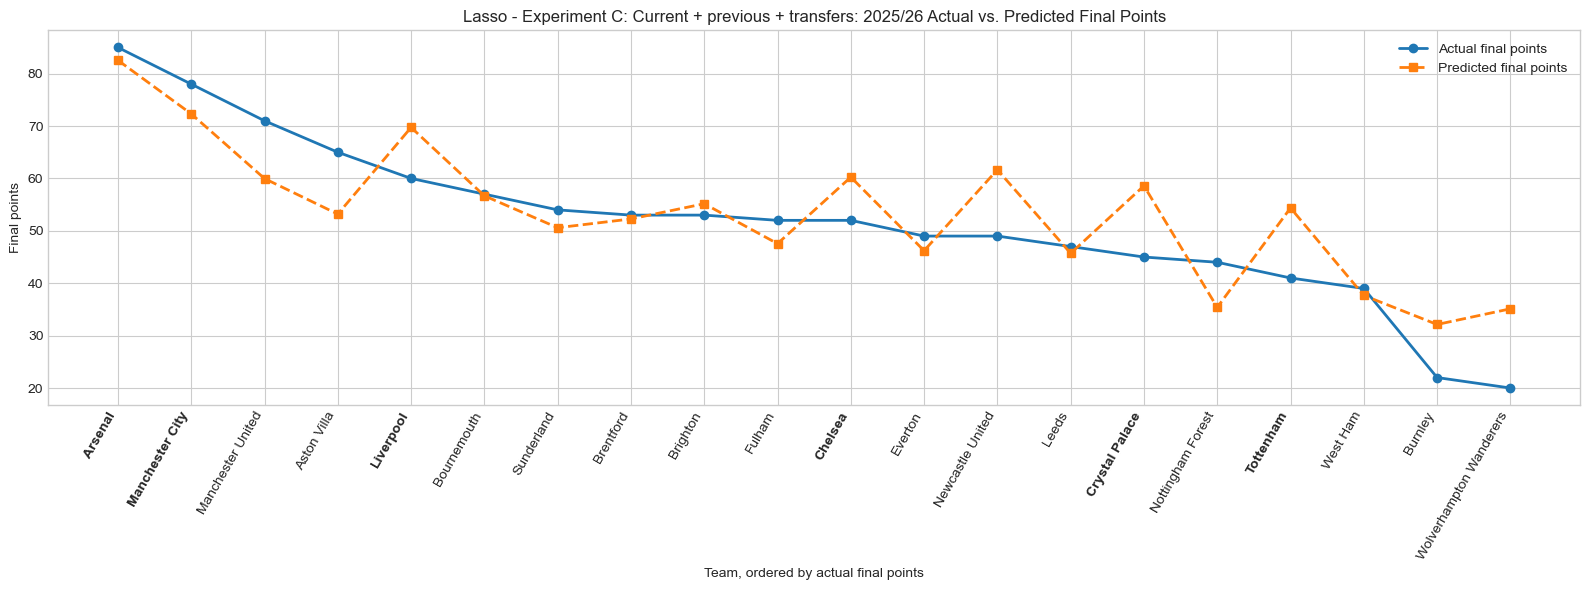

In [11]:
experiment_c_results = [
    result
    for result in all_results
    if result["Experiment"].startswith("Experiment C:")
]

for result in experiment_c_results:
    plot_standard_diagnostics(result)
